In [17]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np

In [18]:
# Load World Happiness data (2016)
happiness_df = pd.read_csv("../../data/raw/2016.csv")

# Structural overview
print(f"Dataset shape: {happiness_df.shape}")
print("-" * 50)
happiness_df.info()

Dataset shape: (157, 13)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157 entries, 0 to 156
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        157 non-null    object 
 1   Region                         157 non-null    object 
 2   Happiness Rank                 157 non-null    int64  
 3   Happiness Score                157 non-null    float64
 4   Lower Confidence Interval      157 non-null    float64
 5   Upper Confidence Interval      157 non-null    float64
 6   Economy (GDP per Capita)       157 non-null    float64
 7   Family                         157 non-null    float64
 8   Health (Life Expectancy)       157 non-null    float64
 9   Freedom                        157 non-null    float64
 10  Trust (Government Corruption)  157 non-null    float64
 11  Generosity                     157

In [19]:
happiness_df.isnull().sum()

Country                          0
Region                           0
Happiness Rank                   0
Happiness Score                  0
Lower Confidence Interval        0
Upper Confidence Interval        0
Economy (GDP per Capita)         0
Family                           0
Health (Life Expectancy)         0
Freedom                          0
Trust (Government Corruption)    0
Generosity                       0
Dystopia Residual                0
dtype: int64

In [20]:
duplicated_values = happiness_df.duplicated()
duplicated_values.sum()


np.int64(0)

In [21]:
display(happiness_df.select_dtypes(include='number').describe().T)

,count,mean,std,min,25%,50%,75%,max
Happiness Rank,157.0,78.980892,45.466030,1.00000,40.00000,79.00000,118.00000,157.00000
Happiness Score,157.0,5.382185,1.141674,2.90500,4.40400,5.31400,6.26900,7.52600
Lower Confidence Interval,157.0,5.282395,1.148043,2.73200,4.32700,5.23700,6.15400,7.46000
Upper Confidence Interval,157.0,5.481975,1.136493,3.07800,4.46500,5.41900,6.43400,7.66900
Economy (GDP per Capita),157.0,0.953880,0.412595,0.00000,0.67024,1.02780,1.27964,1.82427
Family,157.0,0.793621,0.266706,0.00000,0.64184,0.84142,1.02152,1.18326
Health (Life Expectancy),157.0,0.557619,0.229349,0.00000,0.38291,0.59659,0.72993,0.95277
Freedom,157.0,0.370994,0.145507,0.00000,0.25748,0.39747,0.48453,0.60848
Trust (Government Corruption),157.0,0.137624,0.111038,0.00000,0.06126,0.10547,0.17554,0.50521
Generosity,157.0,0.242635,0.133756,0.00000,0.15457,0.22245,0.31185,0.81971


In [22]:

# Number of features to plot and grid layout
n = len(numeric_cols) # Ahora n = 8 (las 8 variables reales)
ncols = 4
nrows = math.ceil(n / ncols)

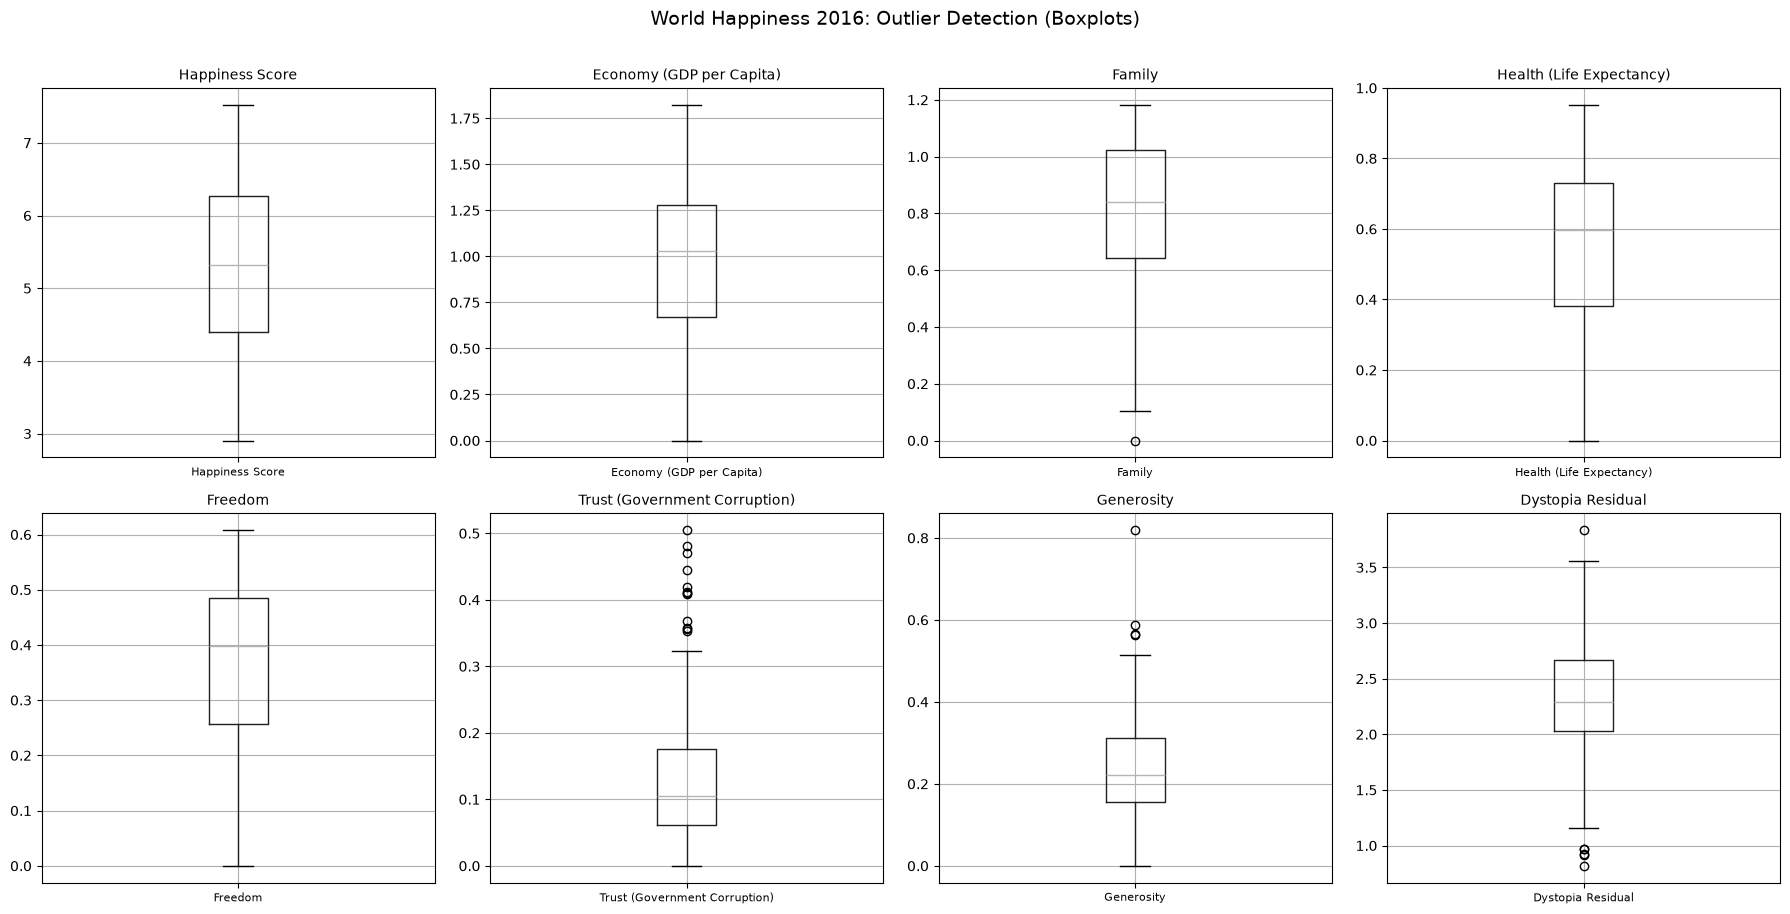

In [32]:

# Auto-detect all numeric columns
numeric_cols = happiness_df.select_dtypes(include=['number']).columns.tolist()

# 🛑 
cols_to_drop = ['Happiness Rank', 'Lower Confidence Interval', 'Upper Confidence Interval']
numeric_cols = [c for c in numeric_cols if c not in cols_to_drop]


# Create the figure and axes grid
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows))
axes = axes.flatten()

# Plot a boxplot for each numeric column
for i, col in enumerate(numeric_cols):
    happiness_df.boxplot(column=col, ax=axes[i], vert=True)
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis="x", labelsize=8)

# Hide ONLY the unused axes
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("World Happiness 2016: Outlier Detection (Boxplots)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

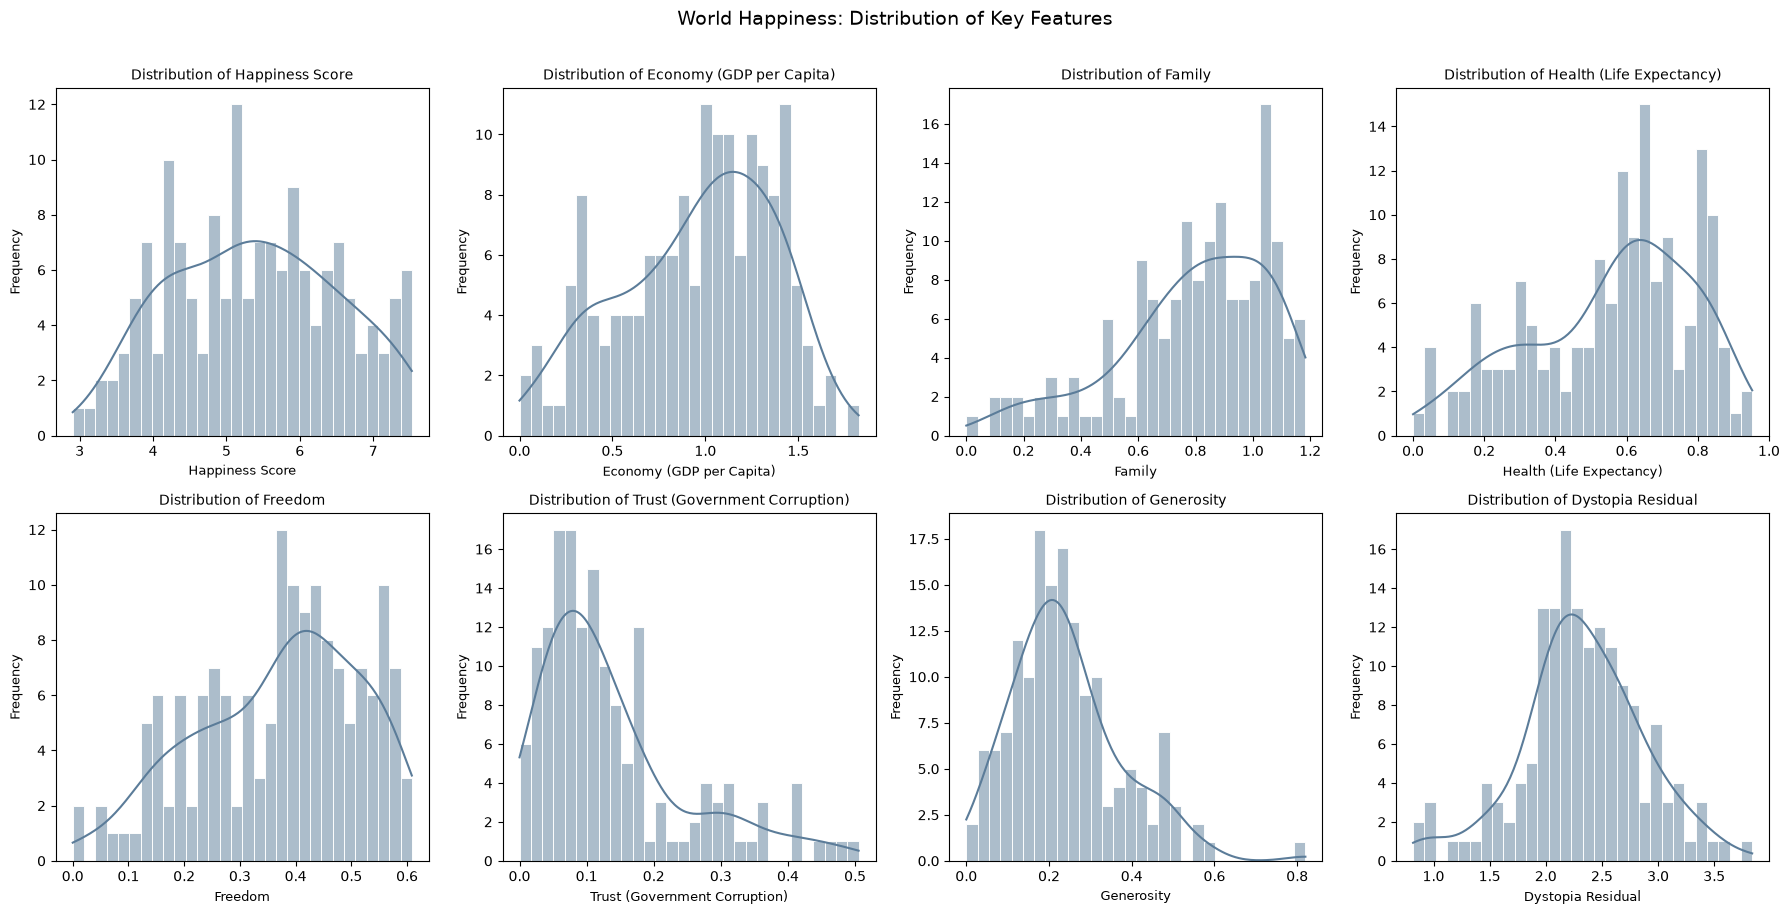

In [ ]:
# 1. Auto-detect ALL numeric columns (regardless of their names)
numeric_cols = happiness_df.select_dtypes(include=['number']).columns.tolist()

# 2. Drop columns that are not useful for distribution analysis
# (This filters out Rank and Confidence Intervals for any year)
cols_to_exclude = [
    'Happiness Rank', 'Overall rank', 'Year', 
    'Lower Confidence Interval', 'Upper Confidence Interval',
    'Lower confidence interval', 'Upper confidence interval'
]
numeric_cols = [c for c in numeric_cols if c not in cols_to_exclude]


# 3. Create the figure
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows))
axes = axes.flatten()

# 4. Plot (Using Seaborn to draw the blue KDE line)
for i, feature in enumerate(numeric_cols):
    sns.histplot(
        happiness_df[feature].dropna(),
        bins=30,
        kde=True,
        ax=axes[i],
        color="#5b7c99",
        edgecolor="white"
    )
    axes[i].set_title(f"Distribution of {feature}", fontsize=10)
    axes[i].set_xlabel(feature, fontsize=9)
    axes[i].set_ylabel("Frequency", fontsize=9)

# 5. Hide unused subplots (if the number of columns is not a multiple of 4)
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("World Happiness: Distribution of Key Features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

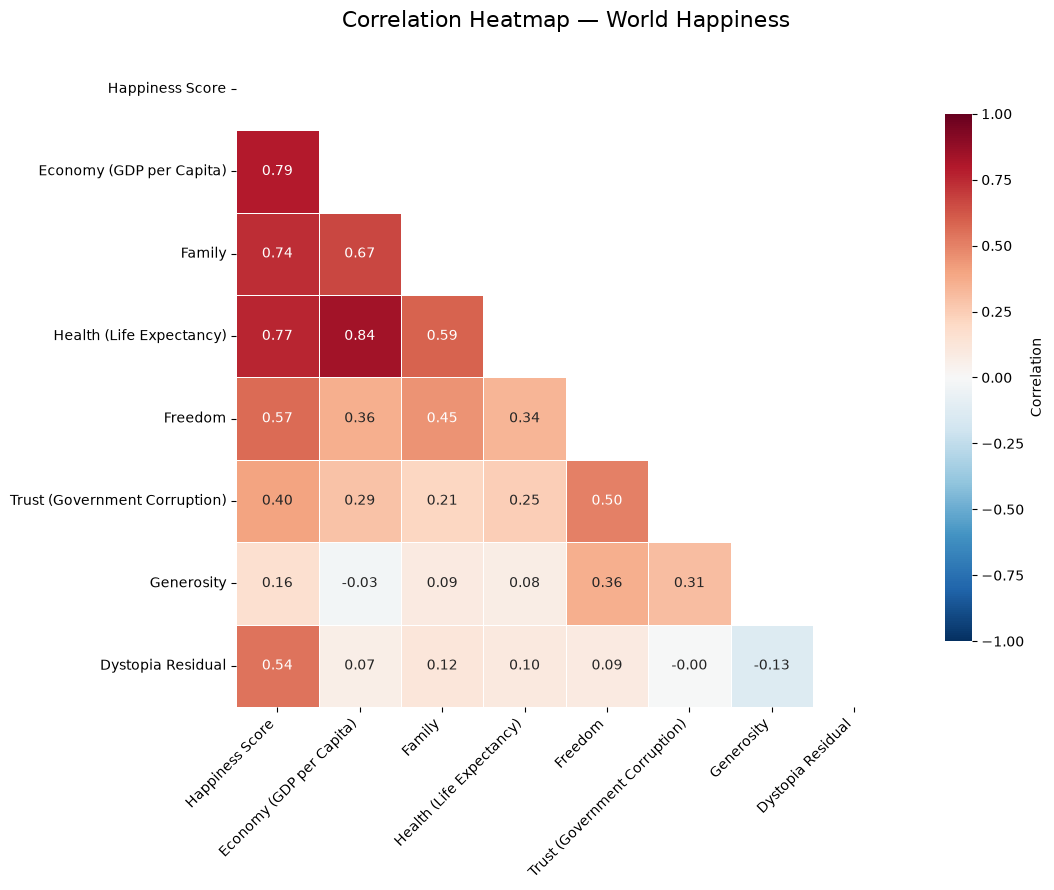

In [ ]:

# 1. Select all numeric columns
numeric_df = happiness_df.select_dtypes(include="number")

# 2. Drop useless columns (Rank, Confidence Intervals, Year)
cols_to_drop = [
    'Happiness Rank', 'Overall rank', 'Year', 
    'Lower Confidence Interval', 'Upper Confidence Interval',
    'Lower confidence interval', 'Upper confidence interval'
]
# Keep only the columns that are not in the drop list
clean_numeric_df = numeric_df.drop(columns=[c for c in cols_to_drop if c in numeric_df.columns])

# 3. Calculate the correlation matrix
corr_matrix = clean_numeric_df.corr()

# 4. Create a mask to hide the upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# 5. Plot the heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",  # Red for positive, Blue for negative
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Correlation"}
)

# Update the title to match the year you are analyzing
plt.title("Correlation Heatmap — World Happiness", fontsize=16, pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

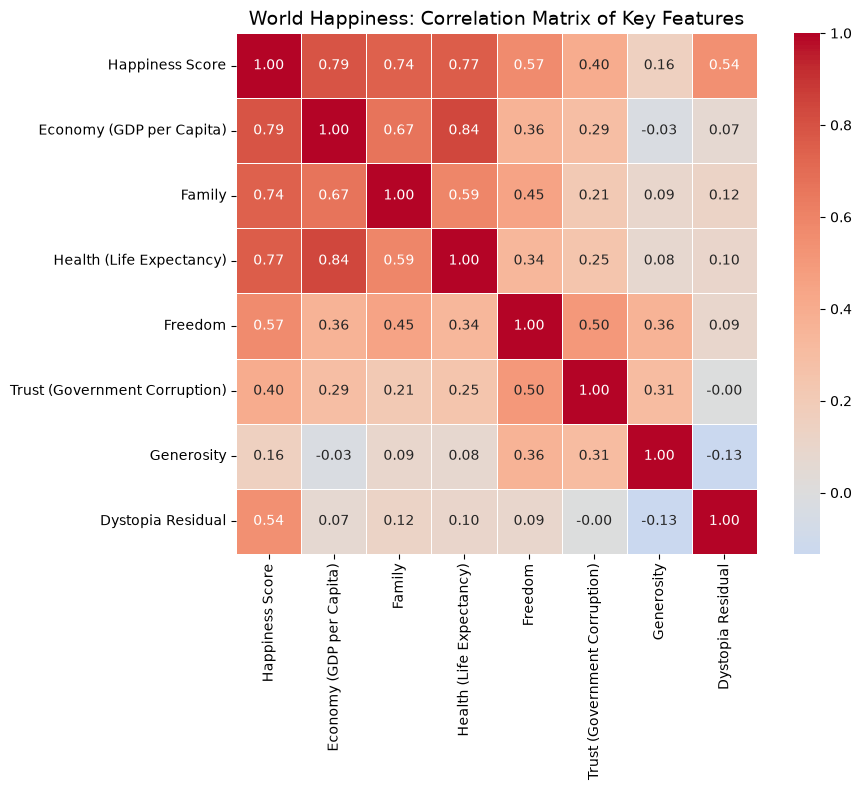

In [30]:
# 1. Auto-detect numeric columns
numeric_cols = happiness_df.select_dtypes(include=['number']).columns.tolist()

# 2. Drop useless columns (Rank, Confidence Intervals, Year)
cols_to_exclude = [
    'Happiness Rank', 'Overall rank', 'Year', 
    'Lower Confidence Interval', 'Upper Confidence Interval',
    'Lower confidence interval', 'Upper confidence interval'
]
clean_cols = [c for c in numeric_cols if c not in cols_to_exclude]

# 3. Calculate correlation matrix
corr = happiness_df[clean_cols].corr()

# 4. Plot the full square heatmap
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr, 
    annot=True,         # Show numbers inside the squares
    fmt=".2f",          # 2 decimal places
    cmap="coolwarm",    # Blue to Red colors
    center=0,           # White is exactly 0
    ax=ax, 
    square=True,        # Make the squares perfectly square
    linewidths=0.5      # Small lines between squares
)

# Update the title depending on the year you are analyzing
ax.set_title("World Happiness: Correlation Matrix of Key Features", fontsize=14)
plt.tight_layout()
plt.show()